# Chicago Crime Forecasting & Hotspot Prediction
Forecast **daily crime counts per police district, 7 days ahead**, and predict **next week's top-20 beats**.
The data is the City of Chicago "Crimes - 2001 to Present" (Socrata `ijzp-q8t2`), 2015 onwards.
Counts are aggregated on the server, so no raw rows are downloaded.

Sections: 0 setup · 1 data + cleaning · 2 EDA + MSTL · 3 features + 4 models · 4 walk-forward backtest + bootstrap CI ·
5 drift + failure cases · 6 hotspot prediction · 7 summary

In [1]:
# 0. Setup. Colab already has most of these; this line makes sure the rest are installed.
%pip -q install duckdb lightgbm holidays statsmodels
import io, time, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, duckdb, requests, holidays, lightgbm as lgb
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import MSTL
from statsmodels.tsa.holtwinters import ExponentialSmoothing

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
DATA, OUT = Path("data"), Path("outputs")
DATA.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)
pd.set_option("display.width", 140, "display.max_columns", 20)

START = "2015-01-01"
# The data window is pinned to the 2026-11-04 API snapshot so reruns query the same dates: SNAPSHOT = day after the last
# record seen then (2026-10-26); END = last record minus 14 days of reporting lag. Socrata still revises past records, so
# later reruns can differ slightly. Set SNAPSHOT = END = None to use the latest data instead.
SNAPSHOT, END = "2026-10-27", "2026-10-12"
BT_START, BT_END = "2023-01-02", "2025-12-31"   # walk-forward backtest window (origins are Mondays)

In [2]:
# 1a. Download: three SoQL GROUP BY queries, all aggregated on the server, cached to data/ as CSV.
API = "https://data.cityofchicago.org/resource/ijzp-q8t2.csv"
WHERE = f"date >= '{START}T00:00:00'" + (f" AND date < '{SNAPSHOT}T00:00:00'" if SNAPSHOT else "")

def soql(name, params, page=50_000):
    """Run a paged SoQL query (cached). Retries with a long timeout: GROUP BY over ~3M rows is slow on Socrata."""
    f = DATA / f"{name}.csv"
    if f.exists():
        return pd.read_csv(f, dtype=str)
    parts, offset = [], 0
    while True:
        for attempt in range(5):
            try:
                r = requests.get(API, params={**params, "$limit": page, "$offset": offset}, timeout=900)
                r.raise_for_status(); break
            except Exception as e:
                if attempt == 4: raise
                print("retry", name, e); time.sleep(15 * (attempt + 1))
        part = pd.read_csv(io.StringIO(r.text), dtype=str)
        parts.append(part)
        if len(part) < page: break
        offset += page
    df = pd.concat(parts, ignore_index=True)
    df.to_csv(f, index=False)
    return df

T_START = time.time()   # whole-notebook timer, reported in the summary cell
t0 = time.time()
q_dq = soql("dq", {"$select": "count(*) AS n_total, sum(case(district IS NULL,1,true,0)) AS n_no_district, "
                              "sum(case(beat IS NULL,1,true,0)) AS n_no_beat, min(date) AS first_date, max(date) AS last_date",
                   "$where": WHERE})
q_daily = soql("daily_district", {"$select": "date_trunc_ymd(date) AS day, district, count(*) AS n",
                                  "$where": WHERE, "$group": "day, district", "$order": "day, district"})
# Weekly per beat: SoQL has no week truncation, so group by (year, month, week-of-year) and rebuild ISO weeks in DuckDB.
# One query per year, run 6 at a time: a single all-years query plus paging takes 10+ min on the server.
from concurrent.futures import ThreadPoolExecutor
def beat_year(yr):
    return soql(f"weekly_beat_{yr}", {"$select": "beat, date_extract_y(date) AS y, date_extract_m(date) AS m, "
                                                 "date_extract_woy(date) AS w, count(*) AS n",
                                      "$where": f"{WHERE} AND date >= '{yr}-01-01T00:00:00' AND date < '{yr+1}-01-01T00:00:00'",
                                      "$group": "beat, y, m, w", "$order": "beat, y, m, w"})
with ThreadPoolExecutor(6) as ex:
    q_beat = pd.concat(ex.map(beat_year, range(int(START[:4]), pd.Timestamp.today().year + 1)), ignore_index=True)
print(f"download/cache load: {time.time()-t0:.0f}s")
print(q_dq.T)
print("aggregated rows downloaded: daily-district", len(q_daily), "| weekly-beat", len(q_beat))

download/cache load: 227s
                                     0
n_total                        2952223
n_no_district                        1
n_no_beat                            0
first_date     2015-01-01T00:00:00.000
last_date      2026-10-26T00:00:00.000
aggregated rows downloaded: daily-district 96718 | weekly-beat 200629


In [3]:
# 1b. Cleaning in DuckDB: valid districts, reporting-lag cutoff, gap check, complete district x day grid.
con = duckdb.connect()
con.register("q_daily", q_daily); con.register("q_beat", q_beat)
# Chicago has 22 active police districts (13, 21 and 23 were merged in 2012). 031 is not a city district.
VALID = [1,2,3,4,5,6,7,8,9,10,11,12,14,15,16,17,18,19,20,22,24,25]
con.execute(f"""CREATE TABLE raw AS SELECT CAST(day AS DATE) AS day, TRY_CAST(district AS INT) AS district,
                CAST(n AS INT) AS n FROM q_daily""")
last_api = con.execute("SELECT max(day) FROM raw").fetchone()[0]
END = pd.Timestamp(END) if END else pd.Timestamp(last_api) - pd.Timedelta(days=14)
END_SQL = END.date().isoformat()
dq = con.execute(f"""
  SELECT
    sum(n)                                                                       AS raw_records,
    sum(n) FILTER (WHERE district IS NULL)                                       AS missing_district,
    sum(n) FILTER (WHERE district IS NOT NULL AND district NOT IN {tuple(VALID)}) AS invalid_district,
    sum(n) FILTER (WHERE day > DATE '{END_SQL}' AND district IN {tuple(VALID)})   AS dropped_reporting_lag,
    sum(n) FILTER (WHERE day <= DATE '{END_SQL}' AND district IN {tuple(VALID)})  AS kept_records
  FROM raw""").df()
print("last day in API:", last_api, "| cutoff (END):", END_SQL)
print(dq.T)
print("invalid district codes:", con.execute(f"SELECT district, sum(n) n FROM raw WHERE district IS NOT NULL AND district NOT IN {tuple(VALID)} GROUP BY 1 ORDER BY 1").fetchall())

con.execute(f"""
  CREATE TABLE daily AS
  WITH grid AS (SELECT CAST(d AS DATE) AS day, district
                FROM range(DATE '{START}', DATE '{END_SQL}' + INTERVAL 1 DAY, INTERVAL 1 DAY) t(d),
                     (SELECT unnest({VALID}) AS district))
  SELECT g.day, g.district, coalesce(r.n, 0) AS y, r.n IS NULL AS filled
  FROM grid g LEFT JOIN raw r USING (day, district) ORDER BY district, day""")
gaps = con.execute("SELECT count(*) FILTER (WHERE filled), count(*) FROM daily").fetchone()
print(f"district-days with no records (date gaps filled with 0): {gaps[0]} of {gaps[1]}")
dd = con.execute("SELECT day, district, y FROM daily").df()
dd["day"] = pd.to_datetime(dd["day"])

last day in API: 2026-10-26 | cutoff (END): 2026-10-12
                               0
raw_records            2952223.0
missing_district             1.0
invalid_district          2632.0
dropped_reporting_lag     8210.0
kept_records           2941380.0
invalid district codes: [(31, 143), (61, 2489)]
district-days with no records (date gaps filled with 0): 0 of 94682


In [4]:
# 1c. Weekly beat counts. Rebuild ISO weeks: Jan days in week 52/53 belong to the previous ISO year, Dec days in week 1 to the next.
con.execute(f"""
  CREATE TABLE beat_raw AS
  WITH t AS (SELECT beat, CAST(y AS INT) y, CAST(m AS INT) m, CAST(w AS INT) w, CAST(n AS INT) n FROM q_beat
             WHERE beat IS NOT NULL),
  iso AS (SELECT *, y + CASE WHEN m = 12 AND w = 1 THEN 1 WHEN m = 1 AND w >= 52 THEN -1 ELSE 0 END AS iy FROM t)
  SELECT beat, make_date(iy, 1, 4) + CAST(7 * (w - 1) - (isodow(make_date(iy, 1, 4)) - 1) AS INTEGER) AS week, sum(n) AS n
  FROM iso GROUP BY 1, 2""")
# Check: city-wide weekly totals rebuilt from beats must equal the daily-district query rolled up to Monday weeks.
chk = con.execute(f"""
  WITH a AS (SELECT week, sum(n) AS n FROM beat_raw GROUP BY 1),
       b AS (SELECT CAST(date_trunc('week', day) AS DATE) AS week, sum(n) AS n FROM raw GROUP BY 1)
  SELECT count(*) AS weeks, sum(abs(a.n - b.n)) AS abs_diff FROM a JOIN b USING (week)""").fetchone()
print("weekly rebuild check (weeks compared, total abs diff vs daily query):", chk)
assert chk[1] == 0, "ISO-week reconstruction does not match daily totals"

WEEK0 = pd.Timestamp(START) + pd.offsets.Week(weekday=0)                 # first full Monday-week
WEEK_END = (END - pd.Timedelta(days=6)).to_period("W-SUN").start_time    # last full week <= END
con.execute(f"""
  CREATE TABLE beats AS
  WITH w AS (SELECT * FROM beat_raw WHERE week BETWEEN DATE '{WEEK0.date()}' AND DATE '{WEEK_END.date()}'),
       pre AS (SELECT * FROM w WHERE week < DATE '{BT_START}'),          -- beat list chosen from pre-backtest weeks only
       nweeks AS (SELECT count(DISTINCT week) k FROM pre),
       keep AS (SELECT beat FROM pre GROUP BY beat HAVING count(*) >= 0.9 * (SELECT k FROM nweeks))
  SELECT wk.week AS week, k.beat AS beat, coalesce(w.n, 0) AS n
  FROM (SELECT DISTINCT week FROM w) wk CROSS JOIN keep k
  LEFT JOIN w ON w.week = wk.week AND w.beat = k.beat
  ORDER BY k.beat, wk.week""")
bw = con.execute("SELECT * FROM beats").df(); bw["week"] = pd.to_datetime(bw["week"])
kept = con.execute("SELECT sum(n) FROM beats").fetchone()[0]
allw = con.execute(f"SELECT sum(n) FROM beat_raw WHERE week BETWEEN DATE '{WEEK0.date()}' AND DATE '{WEEK_END.date()}'").fetchone()[0]
print(f"beats kept: {bw.beat.nunique()} | weeks: {bw.week.nunique()} ({WEEK0.date()}..{WEEK_END.date()}) | "
      f"records in dropped sparse/invalid beats: {allw - kept}")
print("final daily table:", dd.shape, "| final weekly beat table:", bw.shape)

weekly rebuild check (weeks compared, total abs diff vs daily query): (618, 0)
beats kept: 272 | weeks: 614 (2015-01-05..2026-10-05) | records in dropped sparse/invalid beats: 4740
final daily table: (94682, 3) | final weekly beat table: (167008, 3)


**Data-quality notes** *(Numbers below are from the run on 2026-11-04 with the data window pinned to 2015-01-01..2026-10-12.)*
- The API has **2,952,223** records since 2015. Only **96,718** daily-district rows and **200,629** weekly-beat rows were downloaded, because the counting happens on the server.
- Removed: **1** record with no district; **2,632** with non-city district codes (031: 143, 061: 2,489); **8,210** after the 2026-10-12 cutoff (2-week reporting lag). Kept: **2,941,380**.
- Date gaps: **0** of 94,682 district-days had no records, so nothing was imputed. Beats: **272** kept, **4,740** records in sparse or invalid beat codes dropped.
- Check: city-wide weekly totals rebuilt from the beat query match the daily query exactly (618 weeks, 0 difference).

mean daily count by year:
 day
2015    725.8
2016    737.7
2017    737.9
2018    737.5
2019    717.1
2020    581.5
2021    574.7
2022    658.0
2023    721.9
2024    708.6
2025    651.7
2026    641.3
COVID break: 21 Mar-31 May mean 725/day in 2019 vs 491/day in 2020 (-32.2%)


day-of-week ratio: [0.998, 0.983, 0.988, 0.983, 1.036, 1.016, 0.991]
month ratio: [0.915, 0.898, 0.935, 0.946, 1.029, 1.072, 1.094, 1.082, 1.062, 1.037, 0.972, 0.936]
holiday effect (count / same-weekday neighbours), mean over years:
 name
Christmas Day                           0.689
Thanksgiving Day                        0.764
Martin Luther King Jr. Day              0.893
Washington's Birthday                   0.929
Columbus Day                            0.951
Veterans Day                            0.960
Memorial Day                            1.010
Juneteenth National Independence Day    1.020
Labor Day                               1.035
Independence Day                        1.060
New Year's Day                          1.660
1st-of-month ratio 1.251 vs other days 0.994 (offences with unknown dates are often logged on the 1st)


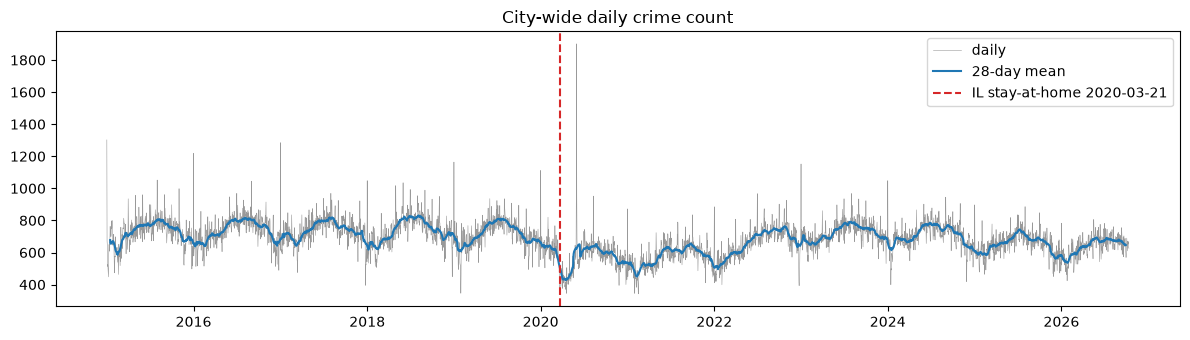

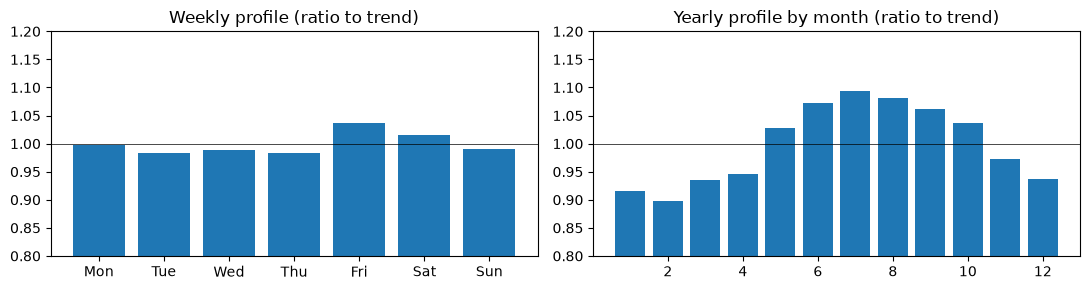

In [5]:
# 2a. EDA: city-wide trend, COVID break, weekly + yearly seasonality, holiday effects.
city = dd.groupby("day")["y"].sum()
us_hol = holidays.US(years=range(2015, 2027))
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(city.index, city.values, lw=0.4, color="0.6", label="daily")
ax.plot(city.rolling(28, center=True).mean(), color="C0", label="28-day mean")
ax.axvline(pd.Timestamp("2020-03-21"), color="C3", ls="--", label="IL stay-at-home 2020-03-21")
ax.set_title("City-wide daily crime count"); ax.legend(); fig.tight_layout(); fig.savefig(OUT / "01_city_daily.png", dpi=110)

yearly = city.groupby(city.index.year).mean().round(1)
print("mean daily count by year:\n", yearly.to_string())
pre = city["2019-03-21":"2019-05-31"].mean(); post = city["2020-03-21":"2020-05-31"].mean()
print(f"COVID break: 21 Mar-31 May mean {pre:.0f}/day in 2019 vs {post:.0f}/day in 2020 ({post/pre-1:+.1%})")

# Seasonality relative to a centered 365-day mean, so the long-term trend does not leak into the profiles.
rel = (city / city.rolling(365, center=True, min_periods=180).mean()).dropna()
dow = rel.groupby(rel.index.dayofweek).mean(); mon = rel.groupby(rel.index.month).mean()
fig, axs = plt.subplots(1, 2, figsize=(11, 3))
axs[0].bar(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"], dow.values); axs[0].set_title("Weekly profile (ratio to trend)")
axs[1].bar(range(1, 13), mon.values); axs[1].set_title("Yearly profile by month (ratio to trend)")
for a in axs: a.axhline(1, color="k", lw=0.5); a.set_ylim(0.8, 1.2)
fig.tight_layout(); fig.savefig(OUT / "02_seasonality.png", dpi=110)
print("day-of-week ratio:", dow.round(3).tolist()); print("month ratio:", mon.round(3).tolist())

# Holiday effect: ratio of a day's count to the mean of the same weekday 1 and 2 weeks before and after.
nb = pd.concat([city.shift(k) for k in (-14, -7, 7, 14)], axis=1).mean(axis=1)
ratio = (city / nb).dropna()
hol = pd.Series({d: n for d, n in us_hol.items()}); hol.index = pd.to_datetime(hol.index)
hr = pd.DataFrame({"name": hol, "ratio": ratio.reindex(hol.index)}).dropna()
hr["name"] = hr["name"].str.replace(r" \(observed\)", "", regex=True)
print("holiday effect (count / same-weekday neighbours), mean over years:\n",
      hr.groupby("name")["ratio"].mean().sort_values().round(3).to_string())
dom1 = ratio[ratio.index.day == 1].mean(); other = ratio[ratio.index.day != 1].mean()
print(f"1st-of-month ratio {dom1:.3f} vs other days {other:.3f} (offences with unknown dates are often logged on the 1st)")

**EDA findings**
- **Trend:** about 717-738 crimes/day in 2015-2019. 2020-2021 fell to about 575-582, 2023 recovered to 722, and 2025 dropped to 652.
- **COVID break:** 21 Mar - 31 May 2020 averaged 491/day against 725/day in the same weeks of 2019 (**-32.2%**). This is a structural break that models trained on 2015-2019 have to survive.
- **Seasonality:** strong yearly cycle, with July 9.4% above trend and February 10.2% below. The weekly cycle is weaker; Friday is highest (+3.6%).
- **Holidays:** Christmas (-31%) and Thanksgiving (-24%) are much lower than neighbouring same weekdays. New Year's Day (+66%) and the 1st of every month (+25%) are high. That is most likely a recording artifact, since offences with an unknown exact date (fraud, for example) are often dated on the 1st. Either way, it is a pattern the model has to learn from calendar features.

share of detrended variance: weekly 8.1%, yearly 48.8%, residual 37.3%
trend level at start / 2019-12-31 / 2020-06-30 / end: [720, 653, 582, 626]


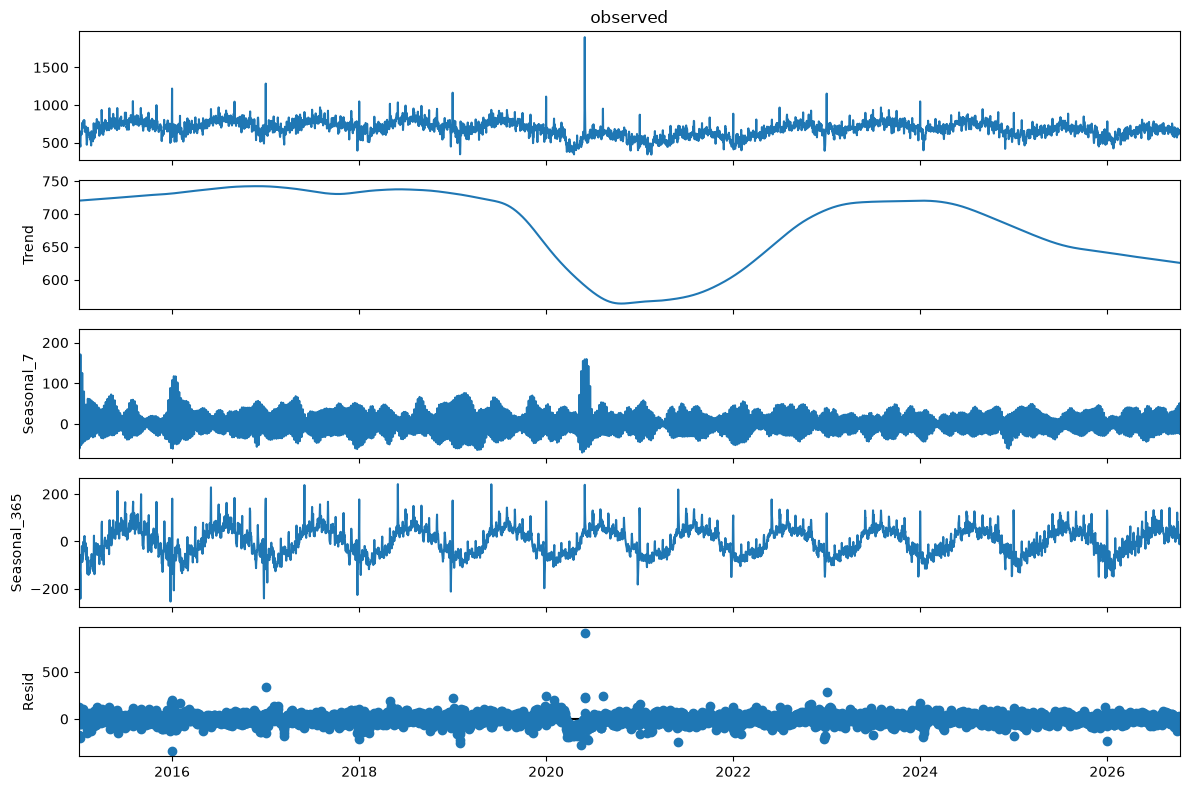

In [6]:
# 2b. MSTL (multi-seasonal STL, periods 7 and 365) on the city-wide daily series.
res = MSTL(city, periods=(7, 365)).fit()
fig = res.plot(); fig.set_size_inches(12, 8); fig.tight_layout(); fig.savefig(OUT / "03_mstl.png", dpi=110)
var = lambda s: np.var(s)
print(f"share of detrended variance: weekly {var(res.seasonal['seasonal_7'])/var(city-res.trend):.1%}, "
      f"yearly {var(res.seasonal['seasonal_365'])/var(city-res.trend):.1%}, residual {var(res.resid)/var(city-res.trend):.1%}")
print("trend level at start / 2019-12-31 / 2020-06-30 / end:",
      [round(res.trend.iloc[0]), round(res.trend["2019-12-31"]), round(res.trend["2020-06-30"]), round(res.trend.iloc[-1])])

**MSTL:** the yearly component explains 48.8% of the detrended variance, the weekly component 8.1%, and the residual 37.3%. The trend fell from 720 (2015) to 582 (mid-2020) and was 626 at the end of the data. Most of what is predictable is seasonal and level-related, which is why lag-364, the rolling mean and the month feature matter.

In [7]:
# 3a. Feature engineering. Every lag is >= 7 days (the horizon), so all features for the 7 target days are known at the forecast origin.
df = dd.sort_values(["district", "day"]).reset_index(drop=True)
g = df.groupby("district")["y"]
for L in (7, 14, 21, 28, 364):
    df[f"lag{L}"] = g.shift(L)
df["rmean28"] = g.transform(lambda s: s.shift(7).rolling(28).mean())
df["rstd28"] = g.transform(lambda s: s.shift(7).rolling(28).std())
df["dow"] = df["day"].dt.dayofweek
df["month"] = df["day"].dt.month
df["holiday"] = df["day"].isin(pd.to_datetime(list(us_hol.keys()))).astype(int)
df["district_c"] = df["district"].astype("category")
FEATS = ["lag7", "lag14", "lag28", "lag364", "rmean28", "rstd28", "dow", "month", "holiday", "district_c"]
# Baselines are just columns: seasonal naive = same weekday last week; mean of the last 4 same weekdays.
df["snaive"] = df["lag7"]
df["mean4"] = df[["lag7", "lag14", "lag21", "lag28"]].mean(axis=1)
df = df[df["day"] >= df["day"].min() + pd.Timedelta(days=364)].reset_index(drop=True)  # lag364 needs a full year
print(df[FEATS].isna().sum().sum(), "missing feature values;", df.shape, df.day.min().date(), df.day.max().date())

LGB_PARAMS = dict(objective="poisson", n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=50,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, deterministic=True,
                  force_row_wise=True, verbose=-1)

def fit_lgb(train):
    return lgb.LGBMRegressor(**LGB_PARAMS).fit(train[FEATS], train["y"])

def hw_forecast(hist, h=7):
    """Holt-Winters: damped additive trend + additive weekly seasonality, fit on the last 2 years."""
    m = ExponentialSmoothing(hist[-730:].astype(float), trend="add", damped_trend=True,
                             seasonal="add", seasonal_periods=7).fit()
    return np.clip(m.forecast(h), 0, None)

0 missing feature values; (86674, 16) 2015-12-31 2026-10-12


In [8]:
# 3b + 4. Walk-forward backtest: a new origin every 28 days, retrain on everything before the origin, predict the next 7 days.
# LightGBM runs from 2020 (needed for the drift study); the model comparison uses the 2023-2025 origins.
origins = pd.date_range("2020-01-06", BT_END, freq="28D")
origins = origins[origins + pd.Timedelta(days=6) <= pd.Timestamp(BT_END)]
assert pd.Timestamp(BT_START) in origins
timing = {"seasonal_naive": 0.0, "mean_4_weekdays": 0.0, "holt_winters": 0.0, "lightgbm": 0.0}
frozen = fit_lgb(df[df["day"] <= "2019-12-31"])        # drift study: trained once on 2016-2019, never updated
y_by_d = {d: s.set_index("day")["y"] for d, s in df.groupby("district")}
rows = []
for T in origins:
    test = df[(df["day"] >= T) & (df["day"] < T + pd.Timedelta(days=7))].copy()
    test["origin"] = T
    t = time.perf_counter(); m = fit_lgb(df[df["day"] < T]); test["lightgbm"] = m.predict(test[FEATS])
    dt_lgb = time.perf_counter() - t
    test["lgb_frozen"] = frozen.predict(test[FEATS])
    if T >= pd.Timestamp(BT_START):
        timing["lightgbm"] += dt_lgb
        t = time.perf_counter(); test["seasonal_naive"] = test["snaive"]; timing["seasonal_naive"] += time.perf_counter() - t
        t = time.perf_counter(); test["mean_4_weekdays"] = test["mean4"]; timing["mean_4_weekdays"] += time.perf_counter() - t
        t = time.perf_counter()
        for d, idx in test.groupby("district").groups.items():
            s = y_by_d[d]; test.loc[idx, "holt_winters"] = hw_forecast(s[s.index < T].values)
        timing["holt_winters"] += time.perf_counter() - t
    rows.append(test)
bt_all = pd.concat(rows, ignore_index=True)
bt = bt_all[bt_all["origin"] >= BT_START].copy()
MODELS = ["seasonal_naive", "mean_4_weekdays", "holt_winters", "lightgbm"]
print(f"origins: {len(origins)} total, {bt.origin.nunique()} in {BT_START[:4]}-{BT_END[:4]} backtest; "
      f"{len(bt)} district-day forecasts per model")

origins: 78 total, 39 in 2023-2025 backtest; 6006 district-day forecasts per model


In [9]:
# 4a. Metrics: MAE, RMSE, WAPE overall + compute time (total over all backtest origins: train + predict).
def metr(y, p):
    e = y - p
    return pd.Series({"MAE": np.mean(np.abs(e)), "RMSE": np.sqrt(np.mean(e**2)), "WAPE_%": 100 * np.abs(e).sum() / y.sum()})

overall = pd.DataFrame({m: metr(bt["y"], bt[m]) for m in MODELS}).T
overall["time_s"] = pd.Series(timing)
overall = overall.round(3)
print(overall)

                   MAE   RMSE  WAPE_%   time_s
seasonal_naive   7.314  9.448  23.176    0.013
mean_4_weekdays  5.682  7.368  18.004    0.012
holt_winters     5.308  6.860  16.818  211.042
lightgbm         5.197  6.677  16.467   32.729


In [10]:
# 4b. Breakdowns: MAE per district, per day of week, holiday vs not.
mae = lambda g: pd.Series({m: np.mean(np.abs(g["y"] - g[m])) for m in MODELS})
by_dist = bt.groupby("district").apply(mae).round(2)
by_dist["lgb_vs_naive_%"] = (100 * (1 - by_dist["lightgbm"] / by_dist["seasonal_naive"])).round(1)
by_dow = bt.groupby("dow").apply(mae).round(2); by_dow.index = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]
by_hol = bt.groupby("holiday").apply(mae).round(2); by_hol.index = ["normal day", "US holiday"]
by_hol["n_rows"] = bt.groupby("holiday").size().values
print("MAE per district:\n", by_dist, "\n\nMAE per day of week:\n", by_dow, "\n\nMAE holiday vs not:\n", by_hol)
print("LightGBM beats seasonal naive in", (by_dist["lgb_vs_naive_%"] > 0).sum(), "of", len(by_dist), "districts")

MAE per district:
           seasonal_naive  mean_4_weekdays  holt_winters  lightgbm  lgb_vs_naive_%
district                                                                         
1                   7.91             6.44          6.23      5.29            33.1
2                   8.42             6.12          5.79      5.63            33.1
3                   7.79             6.10          5.66      5.51            29.3
4                   8.10             6.73          6.01      5.94            26.7
5                   6.70             5.33          4.93      4.85            27.6
6                   7.56             6.30          5.92      5.81            23.1
7                   6.64             5.06          4.74      4.43            33.3
8                   9.37             7.24          6.88      6.87            26.7
9                   7.43             5.58          4.99      5.06            31.9
10                  6.32             5.20          4.96      4.81            23

In [11]:
# 4c. Paired bootstrap 95% CI of the MAE improvement of LightGBM over seasonal naive.
# Resampling unit = forecast origin (a 7-day x 22-district block), because errors inside one week are correlated.
ae = bt.assign(e_n=(bt["y"] - bt["seasonal_naive"]).abs(), e_l=(bt["y"] - bt["lightgbm"]).abs())
blk = ae.groupby("origin")[["e_n", "e_l"]].agg(["sum", "count"])
sn, sl, cnt = blk[("e_n", "sum")].values, blk[("e_l", "sum")].values, blk[("e_n", "count")].values
rng = np.random.default_rng(SEED)
idx = rng.integers(0, len(sn), size=(1000, len(sn)))
diff = (sn[idx].sum(1) - sl[idx].sum(1)) / cnt[idx].sum(1)            # MAE(naive) - MAE(LightGBM)
pct = 100 * diff / (sn[idx].sum(1) / cnt[idx].sum(1))
point = (sn.sum() - sl.sum()) / cnt.sum()
boot = {"mae_improvement": round(float(point), 3), "ci95": [round(float(x), 3) for x in np.percentile(diff, [2.5, 97.5])],
        "pct_improvement": round(float(100 * point / (sn.sum() / cnt.sum())), 1),
        "pct_ci95": [round(float(x), 1) for x in np.percentile(pct, [2.5, 97.5])], "share_resamples_gt0": float((diff > 0).mean())}
print(boot)

{'mae_improvement': 2.117, 'ci95': [1.896, 2.382], 'pct_improvement': 28.9, 'pct_ci95': [26.6, 31.5], 'share_resamples_gt0': 1.0}


**Backtest results (2023-2025, 39 origins x 7 days x 22 districts = 6,006 forecasts per model)**
- LightGBM is best on all three metrics (MAE 5.20, RMSE 6.68, WAPE 16.5%), against seasonal naive's MAE 7.31 and WAPE 23.2%. It beats seasonal naive in **all 22 districts** (22.6-33.8%).
- Holt-Winters is close (MAE 5.31) but is **several times slower** than LightGBM (see `time_s`: 211 s against 33 s on a laptop, 298 s against 93 s on Colab), because it fits 858 separate models versus 39 global ones.
- **Holidays are the biggest gap:** on the 198 holiday rows, seasonal naive's MAE rises to 10.33 while LightGBM's is 5.96, likely helped by its holiday flag.
- **Bootstrap (resampling 39 origin blocks, 1,000 times):** MAE improvement over seasonal naive is 2.12 (95% CI 1.90-2.38), or **28.9% (95% CI 26.6-31.5%)**. All 1,000 resamples favour LightGBM.

      MAE_retrained  MAE_frozen  bias_retrained  bias_frozen  mean_y  frozen_penalty_%
yr                                                                                    
2020           5.90        6.30            0.56         2.00   27.20              6.73
2021           4.95        5.29            0.54         2.27   26.28              6.80
2022           5.26        5.51           -0.07         1.01   29.51              4.78
2023           5.34        5.50           -0.35         0.01   32.48              2.86
2024           5.14        5.32           -0.28         0.11   32.38              3.67
2025           5.11        5.41            0.81         1.74   29.60              5.82


worst origin 2020-05-25: MAE retrained 16.02, frozen 15.76; city-wide 30 May-1 Jun 2020: [926, 1901, 959] vs mean 542/day for the rest of May-June 2020


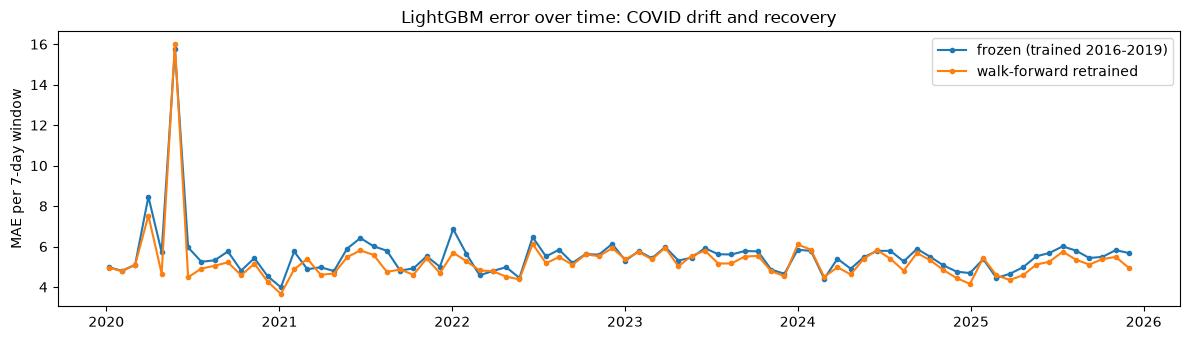

In [12]:
# 5a. Drift: a frozen model trained on 2016-2019 vs the walk-forward retrained model, 2020-2025.
per_o = bt_all.groupby("origin").apply(lambda g: pd.Series({
    "retrained": np.mean(np.abs(g.y - g.lightgbm)), "frozen": np.mean(np.abs(g.y - g.lgb_frozen)),
    "bias_frozen": np.mean(g.lgb_frozen - g.y)}))
by_year = bt_all.assign(yr=bt_all.origin.dt.year).groupby("yr").apply(lambda g: pd.Series({
    "MAE_retrained": np.mean(np.abs(g.y - g.lightgbm)), "MAE_frozen": np.mean(np.abs(g.y - g.lgb_frozen)),
    "bias_retrained": np.mean(g.lightgbm - g.y), "bias_frozen": np.mean(g.lgb_frozen - g.y), "mean_y": g.y.mean()}))
by_year["frozen_penalty_%"] = 100 * (by_year.MAE_frozen / by_year.MAE_retrained - 1)
by_year = by_year.round(2)
print(by_year)
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(per_o.index, per_o.frozen, "o-", ms=3, label="frozen (trained 2016-2019)")
ax.plot(per_o.index, per_o.retrained, "o-", ms=3, label="walk-forward retrained")
ax.set_ylabel("MAE per 7-day window"); ax.set_title("LightGBM error over time: COVID drift and recovery"); ax.legend()
fig.tight_layout(); fig.savefig(OUT / "04_drift.png", dpi=110)
worst_o = per_o.retrained.idxmax()
unrest = city["2020-05-30":"2020-06-01"]
normal = city["2020-05-01":"2020-06-30"].drop(pd.date_range("2020-05-30", "2020-06-02")).mean()
print(f"worst origin {worst_o.date()}: MAE retrained {per_o.retrained.max():.2f}, frozen {per_o.frozen[worst_o]:.2f}; "
      f"city-wide 30 May-1 Jun 2020: {unrest.tolist()} vs mean {normal:.0f}/day for the rest of May-June 2020")

In [13]:
# 5b. PSI (population stability index) of the main features: 2016-2019 (reference) vs 2020-2025.
def psi(ref, new, bins=10):
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
    p = np.clip(np.histogram(ref, edges)[0] / len(ref), 1e-6, None)
    q = np.clip(np.histogram(new, edges)[0] / len(new), 1e-6, None)
    return float(np.sum((q - p) * np.log(q / p)))

ref = df[df.day <= "2019-12-31"]; new = df[(df.day >= "2020-01-01") & (df.day <= BT_END)]
psi_tab = pd.Series({c: psi(ref[c].values, new[c].values) for c in ["y", "lag7", "lag364", "rmean28", "rstd28"]}).round(3)
print("PSI (0.1-0.25 moderate shift, >0.25 major shift):\n", psi_tab.to_string())

PSI (0.1-0.25 moderate shift, >0.25 major shift):
 y          0.116
lag7       0.114
lag364     0.089
rmean28    0.195
rstd28     0.088


In [14]:
# 5c. The 3 biggest failures of the backtested LightGBM model: district x 7-day window, ranked by MAE.
win = bt.groupby(["district", "origin"]).apply(lambda g: pd.Series({
    "MAE": np.mean(np.abs(g.y - g.lightgbm)), "actual_mean": g.y.mean(), "pred_mean": g.lightgbm.mean(),
    "max_day_actual": g.y.max(), "max_day": g.loc[g.y.idxmax(), "day"].date(),
    "holidays": ", ".join(us_hol.get(d) for d in g.day if d in us_hol) or "-"})).reset_index()
worst = win.sort_values("MAE", ascending=False).head(3)
print(worst.round(1).to_string(index=False))
for _, r in worst.iterrows():   # daily detail, to see whether the miss is one spike day or a level shift
    g = bt[(bt.district == r.district) & (bt.origin == r.origin)]
    print(f"district {r.district}, week of {r.origin.date()}: actual {g.y.tolist()} | predicted {g.lightgbm.round(0).astype(int).tolist()}")

 district     origin  MAE  actual_mean  pred_mean  max_day_actual    max_day                             holidays
        8 2024-09-09 15.2         58.7       46.7              76 2024-09-13                                    -
       19 2024-06-17 15.0         51.4       45.9              80 2024-06-22 Juneteenth National Independence Day
       19 2023-06-19 13.8         52.0       42.3             124 2023-06-25 Juneteenth National Independence Day
district 8, week of 2024-09-09: actual [37, 57, 56, 56, 76, 56, 73] | predicted [48, 46, 45, 45, 48, 47, 47]
district 19, week of 2024-06-17: actual [53, 56, 42, 32, 52, 80, 45] | predicted [41, 41, 40, 43, 44, 46, 67]
district 19, week of 2023-06-19: actual [29, 40, 32, 38, 46, 55, 124] | predicted [38, 38, 38, 38, 41, 41, 63]


**Drift and failure findings**
- **Frozen vs retrained:** the frozen 2016-2019 model is 2.9-6.8% worse than the retrained model each year. Its lag features carry the new level, which probably keeps the gap small. It **over-predicts by +2.00 / +2.27 crimes per district-day in 2020 / 2021**, against +0.56 / +0.54 for the retrained model. The gap shrinks to 2.9% in 2023 as crime recovers, then widens again in 2025 (frozen bias +1.74, retrained +0.81) as crime falls. Retraining every 28 days cuts the bias by 53-76% in 2020, 2021 and 2025.
- **Biggest spike in the plot:** the window that starts 2020-05-25 contains **31 May 2020**, the civil unrest after George Floyd's murder (1,901 crimes city-wide against a mean of 542/day for the rest of May-June 2020). Both models miss it equally (MAE 16.02 retrained, 15.76 frozen), because no lag can anticipate it.
- **PSI (2016-2019 vs 2020-2025):** the rolling 28-day mean shifted moderately (0.195). The target and lag-7 are around the 0.1 threshold (0.116, 0.114). Nothing exceeds 0.25.
- **The 3 biggest failures** (MAE per district-week; the causes are likely explanations, not proven):
  1. **District 8, week of 2024-09-09 (MAE 15.2):** every day was above forecast (mean 58.7 against 46.7) with no holiday. A sustained level jump whose cause the counts do not reveal. A 7-day-lagged model cannot react inside the week.
  2. **District 19, week of 2024-06-17 (MAE 15.0):** the model predicted 67 for Sunday 23 June, probably because lag-364 remembered the 2023 spike below. The Pride Parade (route through Lakeview, district 19) was, to our knowledge, a week later in 2024, so the yearly lag misfired on a moving annual event.
  3. **District 19, week of 2023-06-19 (MAE 13.8):** Sunday 25 June had 124 crimes against a forecast of 63, likely the Pride Parade. A one-day event spike that no feature encodes.

{'weeks': 156, 'beats': 272, 'p@20_lightgbm': 0.575, 'p@20_last_week': 0.467, 'weeks_lgb_better': 131, 'weeks_tied': 18, 'time_s': 61.2}


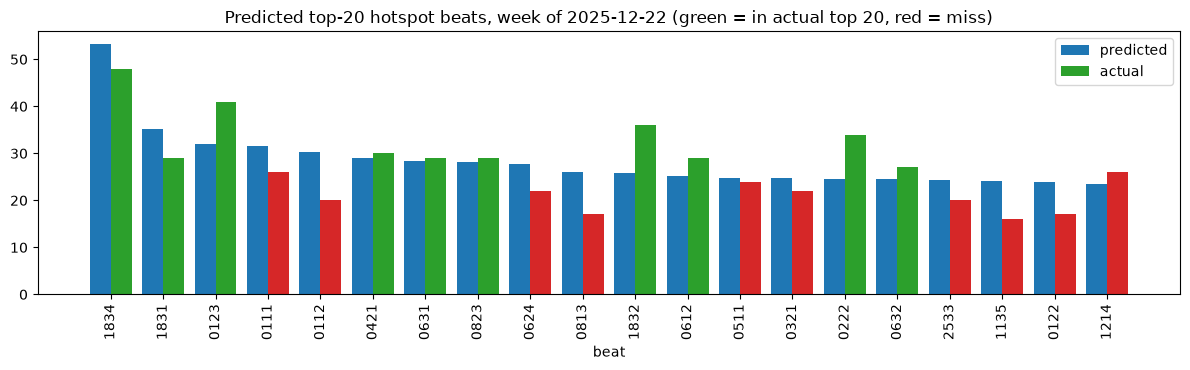

In [15]:
# 6. Hotspots: weekly counts per beat. Each week, predict next week's count per beat and take the top 20.
# LightGBM (retrained every 4 weeks on all earlier weeks) vs. the baseline "last week's top 20".
b = bw.sort_values(["beat", "week"]).reset_index(drop=True)
gb = b.groupby("beat")["n"]
for L in (1, 2, 4, 52):
    b[f"lag{L}"] = gb.shift(L)
b["rmean4"] = gb.transform(lambda s: s.shift(1).rolling(4).mean())
b["rmean13"] = gb.transform(lambda s: s.shift(1).rolling(13).mean())
b["woy"] = b["week"].dt.isocalendar().week.astype(int)
b["beat_c"] = b["beat"].astype("category")
BFEATS = ["lag1", "lag2", "lag4", "lag52", "rmean4", "rmean13", "woy", "beat_c"]
b = b.dropna(subset=BFEATS[:-2]).reset_index(drop=True)
weeks = sorted(b.loc[(b.week >= BT_START) & (b.week <= pd.Timestamp(BT_END) - pd.Timedelta(days=6)), "week"].unique())
K, prec, model, hb_t = 20, [], None, time.perf_counter()
for i, wk in enumerate(weeks):
    if i % 4 == 0:   # retrain every 4 weeks on all weeks strictly before this one
        model = lgb.LGBMRegressor(**LGB_PARAMS).fit(b.loc[b.week < wk, BFEATS], b.loc[b.week < wk, "n"])
    cur = b[b.week == wk].copy(); cur["pred"] = model.predict(cur[BFEATS])
    actual = set(cur.nlargest(K, "n").beat)
    prec.append({"week": wk, "lightgbm": len(actual & set(cur.nlargest(K, "pred").beat)) / K,
                 "last_week_top20": len(actual & set(cur.nlargest(K, "lag1").beat)) / K})
prec = pd.DataFrame(prec)
hb_time = time.perf_counter() - hb_t
hot = {"weeks": len(prec), "beats": b.beat.nunique(), "p@20_lightgbm": round(float(prec.lightgbm.mean()), 3),
       "p@20_last_week": round(float(prec.last_week_top20.mean()), 3),
       "weeks_lgb_better": int((prec.lightgbm > prec.last_week_top20).sum()),
       "weeks_tied": int((prec.lightgbm == prec.last_week_top20).sum()), "time_s": round(hb_time, 1)}
print(hot)

# Chart: the predicted top-20 beats for the last backtest week, predicted vs actual count, hit = also in the actual top 20.
top = cur.nlargest(K, "pred"); hit = top.beat.isin(actual)
fig, ax = plt.subplots(figsize=(12, 3.8)); x = np.arange(K)
ax.bar(x - 0.2, top.pred, 0.4, label="predicted", color="C0")
ax.bar(x + 0.2, top.n, 0.4, label="actual", color=np.where(hit, "C2", "C3"))
ax.set_xticks(x, top.beat, rotation=90); ax.set_xlabel("beat")
ax.set_title(f"Predicted top-20 hotspot beats, week of {pd.Timestamp(wk).date()} (green = in actual top 20, red = miss)")
ax.legend(); fig.tight_layout(); fig.savefig(OUT / "05_hotspots.png", dpi=110)

**Hotspot findings:** over 156 backtest weeks (2023-2025) and 272 beats, LightGBM's precision@20 is **0.575** against **0.467** for "last week's top 20". LightGBM is better in 131 weeks and tied in 18. The model smooths over several weeks (lags 1/2/4/52 plus 4- and 13-week means), which plausibly makes it less sensitive to a single noisy week.

In [16]:
# 7. Summary: every number used in the README, saved to outputs/results.json.
results = {"data": {**dq.iloc[0].astype(int).to_dict(), "api_total_since_2015": int(q_dq.n_total[0]),
                    "api_missing_district": int(q_dq.n_no_district[0]), "end": END_SQL,
                    "daily_rows": len(dd), "weekly_beat_rows": len(bw), "downloaded_rows": len(q_daily) + len(q_beat) + 1},
           "overall": overall.reset_index().to_dict("records"), "bootstrap": boot,
           "drift_by_year": by_year.reset_index().to_dict("records"), "psi": psi_tab.to_dict(), "hotspots": hot}
results["runtime_s"] = round(time.time() - T_START)
(OUT / "results.json").write_text(json.dumps(results, indent=1, default=str))
print(json.dumps(results, indent=1, default=str))

{
 "data": {
  "raw_records": 2952223,
  "missing_district": 1,
  "invalid_district": 2632,
  "dropped_reporting_lag": 8210,
  "kept_records": 2941380,
  "api_total_since_2015": 2952223,
  "api_missing_district": 1,
  "end": "2026-10-12",
  "daily_rows": 94682,
  "weekly_beat_rows": 167008,
  "downloaded_rows": 297348
 },
 "overall": [
  {
   "index": "seasonal_naive",
   "MAE": 7.314,
   "RMSE": 9.448,
   "WAPE_%": 23.176,
   "time_s": 0.013
  },
  {
   "index": "mean_4_weekdays",
   "MAE": 5.682,
   "RMSE": 7.368,
   "WAPE_%": 18.004,
   "time_s": 0.012
  },
  {
   "index": "holt_winters",
   "MAE": 5.308,
   "RMSE": 6.86,
   "WAPE_%": 16.818,
   "time_s": 211.042
  },
  {
   "index": "lightgbm",
   "MAE": 5.197,
   "RMSE": 6.677,
   "WAPE_%": 16.467,
   "time_s": 32.729
  }
 ],
 "bootstrap": {
  "mae_improvement": 2.117,
  "ci95": [
   1.896,
   2.382
  ],
  "pct_improvement": 28.9,
  "pct_ci95": [
   26.6,
   31.5
  ],
  "share_resamples_gt0": 1.0
 },
 "drift_by_year": [
  {
   "yr